# Phase 6 | Calibrated choice model
**Sources:** Phase 4 area-weighted panel, 2024 ACS, Google Maps distances, Dewey reported origin counts.
Fit fractional multinomial shares using equal weight per origin-month, with a Ponce reference intercept. This is conditional on the three study districts; device counts are not mutually exclusive individual choices. Holdout uses the same neighborhoods in later months, not independent new neighborhoods. No missing origin is imputed as zero here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import softmax
from pathlib import Path
D=Path('/mnt/data') if Path('/mnt/data/Phase4_results/panel.csv').exists() else Path('.')
O=D/'Phase6'; O.mkdir(exist_ok=True)
p=pd.read_csv(D/'Phase4_results/panel.csv',dtype={'ZCTA':str}).dropna(subset=['income'])
assert not p.duplicated(['ZCTA','Month','Destination']).any()
names=['Lenox Square','Phipps Plaza','Ponce City Market']
y=p.pivot(index=['ZCTA','Month'],columns='Destination',values='flow')[names].dropna()
d=p.pivot(index=['ZCTA','Month'],columns='Destination',values='driving_miles').loc[y.index,names].values
inc=p.groupby(['ZCTA','Month']).income.first().loc[y.index].values
Y=y.values; shares=Y/Y.sum(axis=1,keepdims=True)
train=y.index.get_level_values('Month')<=9; test=~train
center=np.log(inc[train]).mean()
def predict(b,dist=d):
    u=np.tile([b[0],b[1],0.],(len(y),1))+b[2]*np.log1p(dist)
    if len(b)>3: u+=b[3]*(np.log(inc)-center)[:,None]*np.array([1,1,0])
    return softmax(u,axis=1)
fits={}; rows=[]
for name,k in [('Distance only',3),('Distance + income',4)]:
    def loss(b): return -(shares[train]*np.log(predict(b)[train])).sum()/train.sum()
    fit=minimize(loss,np.zeros(k),method='L-BFGS-B'); assert fit.success,fit.message
    fits[name]=fit.x
    pred=predict(fit.x)
    rows.append([name,*fit.x[:3],fit.x[3] if k==4 else np.nan,np.abs(pred[test]-shares[test]).mean(),-(shares[test]*np.log(pred[test])).sum()/test.sum()])
results=pd.DataFrame(rows,columns=['Model','Lenox intercept','Phipps intercept','Log distance','Income x Buckhead','Test MAE','Test cross entropy'])
print('Training groups:',train.sum(),'Test groups:',test.sum()); display(results)
results.to_csv(O/'validation.csv',index=False)


Training groups: 207 Test groups: 69


,Model,Lenox intercept,Phipps intercept,Log distance,Income x Buckhead,Test MAE,Test cross entropy
0,Distance only,0.418694,0.149350,-1.061188,NaN,0.06185,1.032842
1,Distance + income,0.410838,0.139856,-1.007512,0.307822,0.06034,1.031769


## Holdout validation
Lower MAE and cross entropy indicate better predictions. Compare both models; a predictive improvement does not establish statistical significance or causation.

,Destination,Observed,Predicted
0,Lenox Square,0.384529,0.378322
1,Phipps Plaza,0.290922,0.279039
2,Ponce City Market,0.324549,0.342639


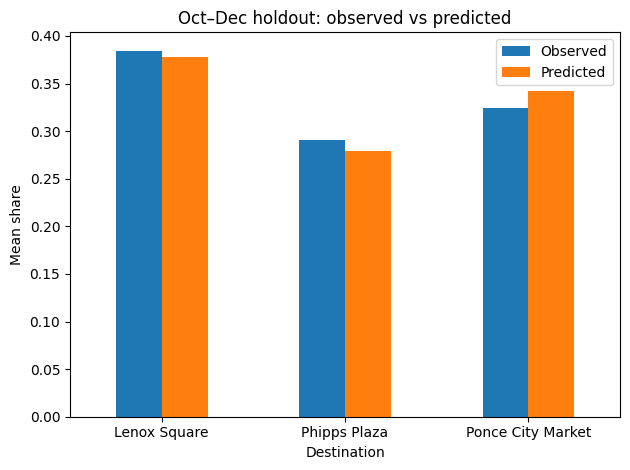

In [2]:
best=results.sort_values('Test cross entropy').iloc[0].Model
b=fits[best]; pred=predict(b)
validation=pd.DataFrame({'Destination':names,'Observed':shares[test].mean(axis=0),'Predicted':pred[test].mean(axis=0)})
display(validation)
validation.to_csv(O/'test_shares.csv',index=False)
validation.set_index('Destination').plot.bar(rot=0,ylabel='Mean share',title='Oct–Dec holdout: observed vs predicted'); plt.tight_layout(); plt.savefig(O/'validation.png'); plt.show()


## Counterfactual distance changes
Change one destination distance at a time, holding other inputs fixed. Average percentage-point change across origin-months. This is a model-based sensitivity exercise, not a causal transport forecast.

,Improved destination,Distance reduction,Lenox Square,Phipps Plaza,Ponce City Market
0,Lenox Square,0.1,2.020021,-0.933529,-1.086493
1,Lenox Square,0.2,4.284619,-1.971538,-2.313082
2,Lenox Square,0.3,6.843390,-3.133761,-3.709628
3,Phipps Plaza,0.1,-0.938910,1.727507,-0.788598
4,Phipps Plaza,0.2,-2.003976,3.701095,-1.697119
5,Phipps Plaza,0.3,-3.224001,5.979943,-2.755942
6,Ponce City Market,0.1,-1.002512,-0.721767,1.724279
7,Ponce City Market,0.2,-2.122516,-1.529359,3.651875
8,Ponce City Market,0.3,-3.384214,-2.440746,5.824960


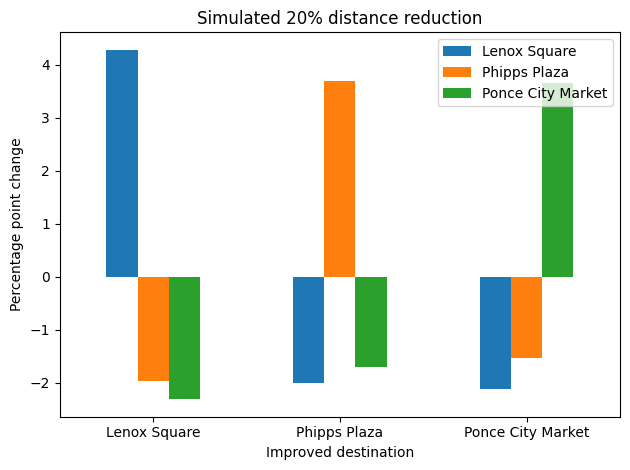

In [3]:
scenarios=[]
for mall in range(3):
    for reduction in [.1,.2,.3]:
        new=d.copy(); new[:,mall]*=1-reduction
        change=(predict(b,new)-pred).mean(axis=0)*100
        scenarios.append([names[mall],reduction,*change])
scenario=pd.DataFrame(scenarios,columns=['Improved destination','Distance reduction',*names]); display(scenario)
scenario.to_csv(O/'counterfactual.csv',index=False)
scenario[scenario['Distance reduction']==.2].set_index('Improved destination')[names].plot.bar(rot=0,ylabel='Percentage point change',title='Simulated 20% distance reduction'); plt.tight_layout(); plt.savefig(O/'counterfactual.png'); plt.show()
